# What does the LDA capture once the wheel is in it?

The paper's mouse-weighted shrinkage LDA (`lda_shrinkage_core.MouseEmbedding`, shrinkage 0.5 as the saved embedding `mouse_LDA_5_bins_raw_shrink0.5_wmouse_360`) refitted on the syllable features **plus the wheel movement states** (3.4, as one-hot per bin; features from `wheel_lda_test.py`), then the two analyses of `fig_ld1`:
1. **syllable correlations**: per trial bin, the correlation across sessions between a state's occupancy and LD1 (permutation band), now including the wheel states;
2. **trial-metric correlations**: `LDA_behavior`'s session summaries (accuracy, bias, RT, elongation, trials, training time) against LD1.

Everything is shown for the new LD1 and, side by side, the production LD1, so the question is what the wheel changes. `VARIANT` picks the wheel state set (`wheel8`: still, small, side × mid / high; `wheel10`: side × vigor).

In [1]:
import sys, pathlib, glob, re
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from scipy.stats import pearsonr
from statsmodels.stats.multitest import multipletests

REPO = pathlib.Path.cwd().resolve()
while not (REPO / 'Functions' / 'trial_modes.py').exists() and REPO != REPO.parent:
    REPO = REPO.parent
PI = REPO / 'paper-individuality'
for p in [PI, PI / 'learning_individuality', PI / '4_mice', PI / 'segmentation']:
    sys.path.insert(0, str(p))
import paper_style as ps
import lda_shrinkage_core as lsc
import wheel_lda_test as wlt
import wheel_movement_clusters as wmc
ps.use('paper', dpi=110); ps.use_paw_states('uniform')

VARIANT = 'wheel17'
K_WHEEL = int(VARIANT[5:])
GROUPING = {8: 'small_side_vigor', 10: 'side_vigor', 17: 'sided_both2', 21: None}[K_WHEEL]
SHRINKAGE = 0.5                  # as the saved production embedding
LDA_FILE = PI / 'clustering' / 'data_files' / 'mouse_LDA_5_bins_raw_shrink0.5_wmouse_360_02-10-2026'
TRIAL_META = PI / 'data' / 'session_trial_meta_19-08-2026'
TRAINING_FILE = REPO / 'learning_prediction' / 'training_time_05-05-2026'
N_PERMS, SEED = 1000, 0
EPOCHS = ps.EPOCH_NAMES
WM = wmc.load_model('proficient', 21)
W_NAMES = wmc.state_names(WM, GROUPING)
W_COLORS = ['#BDBDBD'] + wmc.colours(WM, GROUPING)[1:]       # still drawn mid grey so its line is visible
assert len(W_NAMES) == K_WHEEL

paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi


## Embeddings: production LD1 reproduced, then refitted with the wheel

In [2]:
Xn, mouse = wlt.features(VARIANT)
Xb, mouse_b = wlt.features('base')
assert (Xn.index == Xb.index).all() and (mouse.values == mouse_b.values).all()
prod = pd.read_pickle(LDA_FILE).set_index('session').reindex(Xb.index)
sessions, mice = Xb.index.to_numpy(), mouse.to_numpy()

E_base = lsc.MouseEmbedding(Xb.to_numpy(float), mice, shrinkage=SHRINKAGE)
E_new = lsc.MouseEmbedding(Xn.to_numpy(float), mice, shrinkage=SHRINKAGE)
Zb, Zn = E_base.transform(Xb.to_numpy(float), 3), E_new.transform(Xn.to_numpy(float), 3)
P = prod[[0, 1, 2]].to_numpy(float)
r_repro = [pearsonr(Zb[:, i], P[:, i])[0] for i in range(3)]
print('refit on the production features vs the saved embedding, LD1-3: r =', np.round(r_repro, 4))

# orient each new axis like the production axis it correlates with most
R = np.array([[pearsonr(Zn[:, i], P[:, j])[0] for j in range(3)] for i in range(3)])
for i in range(3):
    Zn[:, i] *= np.sign(R[i, np.argmax(np.abs(R[i]))])
R = np.array([[pearsonr(Zn[:, i], P[:, j])[0] for j in range(3)] for i in range(3)])
mm = lambda Z: pd.DataFrame(Z).groupby(mice).mean().to_numpy()
Rm = np.array([[pearsonr(mm(Zn)[:, i], mm(P)[:, j])[0] for j in range(3)] for i in range(3)])
idx = [f'new LD{i + 1}' for i in range(3)]; cols = [f'production LD{j + 1}' for j in range(3)]
print(f'between-mouse share, production: {np.round(E_base.axis_share[:3], 3)};  with the wheel: {np.round(E_new.axis_share[:3], 3)}')
display(pd.concat({'sessions': pd.DataFrame(R, idx, cols), 'mouse means': pd.DataFrame(Rm, idx, cols)}, axis=1).round(3))
LD = pd.DataFrame({'session': sessions, 'mouse_name': mice, 'LD1_new': Zn[:, 0], 'LD2_new': Zn[:, 1], 'LD3_new': Zn[:, 2],
                   'LD1_prod': P[:, 0], 'LD2_prod': P[:, 1], 'LD3_prod': P[:, 2]})

refit on the production features vs the saved embedding, LD1-3: r = [1. 1. 1.]
between-mouse share, production: [0.136 0.099 0.085];  with the wheel: [0.107 0.086 0.076]


sessions                                  mouse means  \
        production LD1 production LD2 production LD3 production LD1   
new LD1          0.950         -0.146          0.052          0.953   
new LD2          0.181          0.856          0.195          0.166   
new LD3         -0.065         -0.104          0.761         -0.095   

                                       
        production LD2 production LD3  
new LD1         -0.146          0.039  
new LD2          0.877          0.187  
new LD3         -0.141          0.735

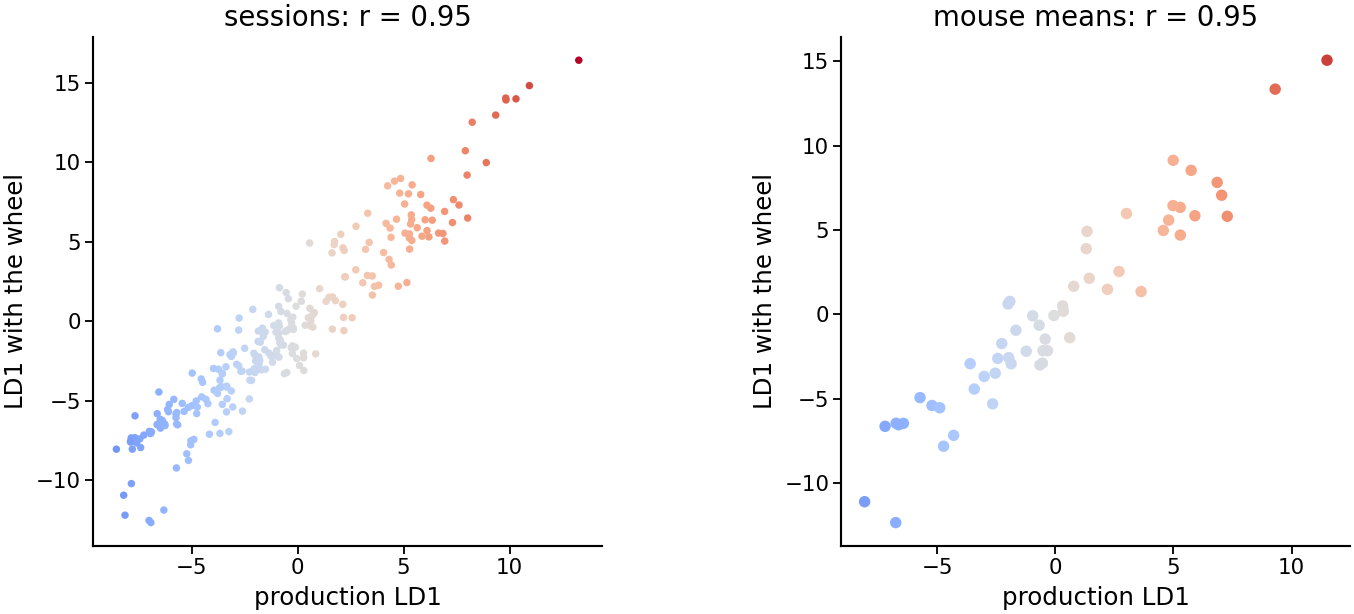

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(7, 3))
for ax, Z_, Pp, lab in [(axs[0], LD.LD1_new, LD.LD1_prod, 'sessions'),
                        (axs[1], LD.groupby('mouse_name').LD1_new.mean(), LD.groupby('mouse_name').LD1_prod.mean(), 'mouse means')]:
    ax.scatter(Pp, Z_, s=6 if lab == 'sessions' else 14, c=ps.LD1_CMAP(ps.ld1_norm(LD.LD1_prod.to_numpy())(np.asarray(Pp))), lw=0)
    ax.set(xlabel='production LD1', ylabel='LD1 with the wheel', title=f'{lab}: r = {pearsonr(Pp, Z_)[0]:.2f}')
    ax.set_box_aspect(1)
plt.tight_layout()

## 1. Syllable correlations along LD1 — including the wheel states

Per trial bin (4 epochs × 10), the correlation across the 260 sessions between a state's occupancy in that bin and LD1. Grey band = 95 % of the same correlation with LD1 permuted across sessions (envelope over the states in a panel); traces solid where they leave it. Top row: the LD1 refitted with the wheel; bottom: the production LD1 (fit without the wheel), to see whether wheel use already lined up with it.

/tmp/ipykernel_44886/579826012.py:22: RuntimeWarning: invalid value encountered in divide
  return (Mc.T @ vc) / (np.sqrt((Mc ** 2).sum(axis=0)) * np.sqrt((vc ** 2).sum()))


/home/ines/miniconda3/envs/iblenv/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:1620: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


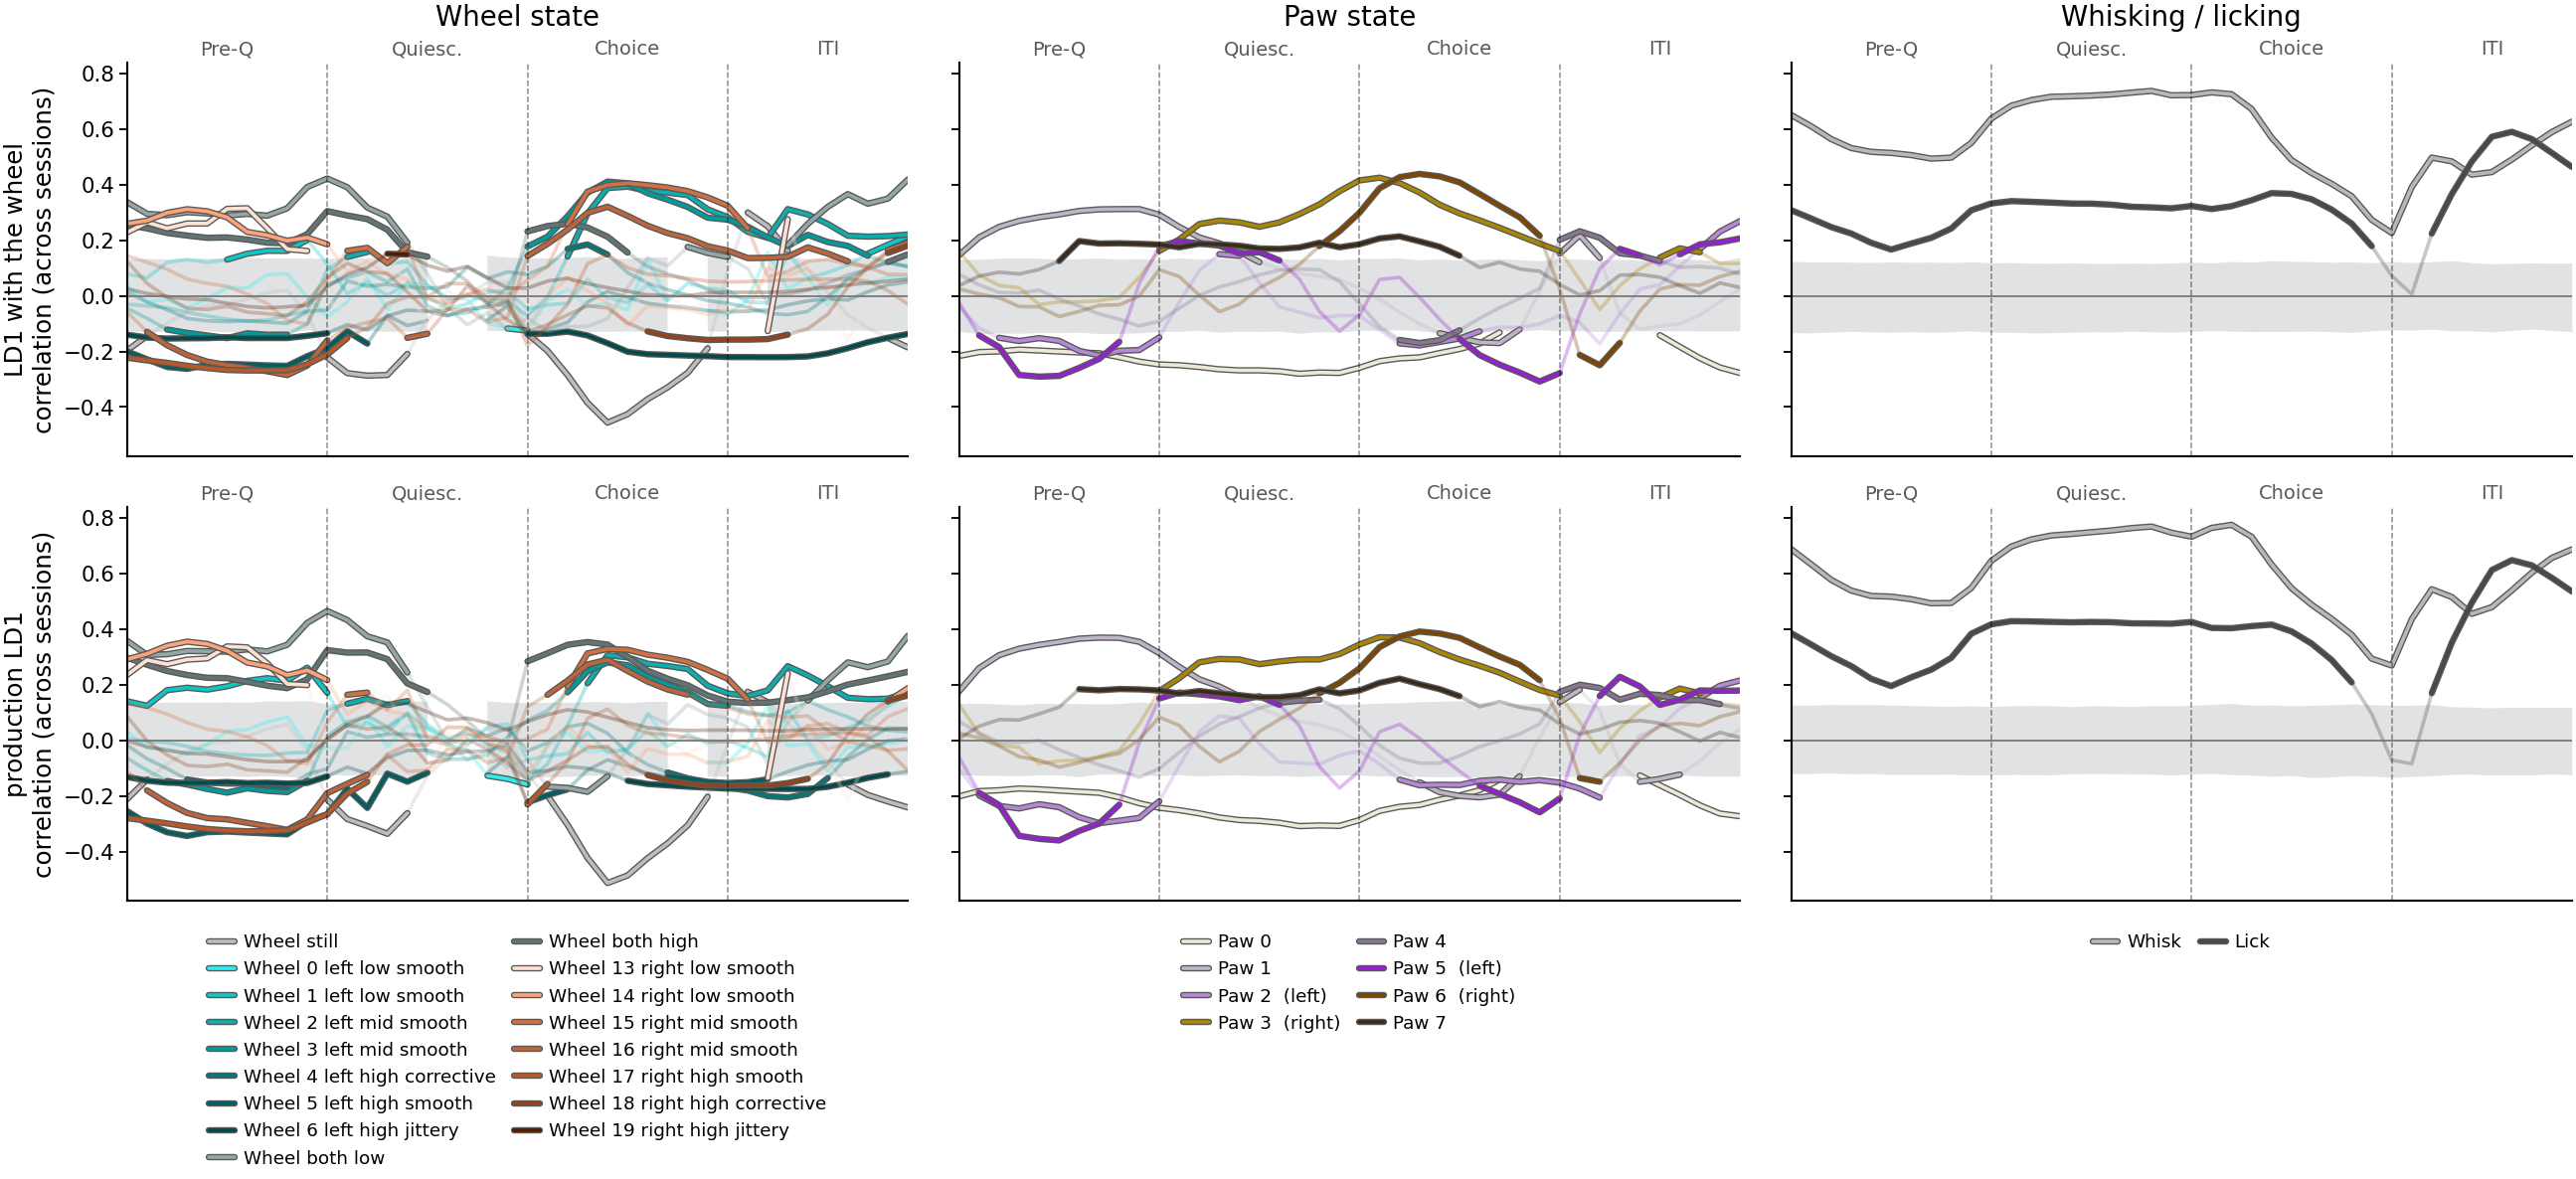

In [4]:
syl = pd.read_parquet(sorted(glob.glob(
    str(PI / 'data' / f'both_paws+wheelmov-sep_k8-{K_WHEEL}_own_lick-standard_proficient_8_k_10_bin_syllables_*')))[-1])
syl['session'] = syl['sample'].str[:36]
syl = syl[syl['session'].isin(sessions)]
tr = (syl.pivot(index=['mouse_name', 'session', 'sample'], columns='broader_label', values=['binned_sequence', 'wheel_binned_sequence'])
      .dropna().reset_index())
stack = lambda col: np.vstack([np.hstack(r) for r in tr[[(col, e) for e in EPOCHS]].to_numpy()]).astype(float)
codes, wheel = ps.paw_codes(stack('binned_sequence')), stack('wheel_binned_sequence')
paw, whisk, lick = ps.decode_syllables(codes)
OCC = np.stack([np.where(np.isnan(paw), np.nan, paw == k) for k in range(ps.N_PAW_STATES)] + [whisk, lick]
               + [np.where(np.isnan(wheel), np.nan, wheel == k) for k in range(K_WHEEL)], axis=-1)
sidx = tr[('session', '')].to_numpy()
with np.errstate(invalid='ignore'):
    SESS_OCC = np.stack([np.nanmean(OCC[sidx == s], axis=0) for s in sessions])     # (sessions, 40, 8 + 2 + K)
N_BINS = SESS_OCC.shape[1]
PAW_F, WL_F, WH_F = list(range(ps.N_PAW_STATES)), [8, 9], list(range(10, 10 + K_WHEEL))
LABEL = [ps.paw_label(k) for k in range(ps.N_PAW_STATES)] + ['Whisk', 'Lick'] + [f'Wheel {n}' for n in W_NAMES]
COLOR = list(ps.SYLLABLE_COLORS) + W_COLORS

def colwise_r(Mx, v):
    Mc = np.nan_to_num(Mx - np.nanmean(Mx, axis=0)); vc = v - v.mean()
    return (Mc.T @ vc) / (np.sqrt((Mc ** 2).sum(axis=0)) * np.sqrt((vc ** 2).sum()))
flat = SESS_OCC.reshape(len(sessions), -1)
STRUCT, BAND = {}, {}
rng = np.random.default_rng(SEED)
for key in ('LD1_new', 'LD1_prod'):
    v = LD[key].to_numpy()
    STRUCT[key] = colwise_r(flat, v).reshape(N_BINS, -1)
    null = np.stack([colwise_r(flat, rng.permutation(v)).reshape(N_BINS, -1) for _ in range(N_PERMS)])
    BAND[key] = np.nanpercentile(null, [2.5, 97.5], axis=0)
OUTLINE = [pe.Stroke(linewidth=plt.rcParams['lines.linewidth'] + 0.9, foreground='0.35'), pe.Normal()]

fig, axs = plt.subplots(2, 3, figsize=(12, 5.6), sharey=True)
for row, key in enumerate(('LD1_new', 'LD1_prod')):
    lo, hi = BAND[key]
    for ax, feats, title in zip(axs[row], [WH_F, PAW_F, WL_F], ['Wheel state', 'Paw state', 'Whisking / licking']):
        x = np.arange(N_BINS)
        ax.fill_between(x, lo[:, feats].min(1), hi[:, feats].max(1), color=ps.NULL_BAND, alpha=0.3, lw=0)
        for f in feats:
            y = STRUCT[key][:, f]
            ax.plot(x, y, color=COLOR[f], alpha=0.3)
            ax.plot(x, np.where((y >= lo[:, f]) & (y <= hi[:, f]), np.nan, y), color=COLOR[f], label=LABEL[f], path_effects=OUTLINE)
        ax.axhline(0, color=ps.NEUTRAL, lw=0.6); ps.epoch_lines(ax, N_BINS, label=True, names=ps.EPOCH_SHORT)
        ax.set(xlim=(0, N_BINS - 1), xticks=[])
        if row == 0: ax.set_title(title, pad=12)
        if row == 1: ax.legend(frameon=False, fontsize=6, ncol=2, loc='upper center', bbox_to_anchor=(0.5, -0.05))
    axs[row, 0].set_ylabel(('LD1 with the wheel' if key == 'LD1_new' else 'production LD1') + '\ncorrelation (across sessions)')
plt.tight_layout()

In [5]:
# summary: how strongly each state's occupancy tracks LD1 (max |r| over bins), new vs production LD1
summ = pd.DataFrame({'state': LABEL,
                     'max|r| with the wheel LD1': np.nanmax(np.abs(STRUCT['LD1_new']), axis=0),
                     'max|r| production LD1': np.nanmax(np.abs(STRUCT['LD1_prod']), axis=0),
                     'bins outside the band (wheel LD1)': ((STRUCT['LD1_new'] < BAND['LD1_new'][0]) | (STRUCT['LD1_new'] > BAND['LD1_new'][1])).sum(0),
                     'bins outside the band (production LD1)': ((STRUCT['LD1_prod'] < BAND['LD1_prod'][0]) | (STRUCT['LD1_prod'] > BAND['LD1_prod'][1])).sum(0)})
summ.round(3)

,state,max|r| with the wheel LD1,max|r| production LD1,bins outside the band (wheel LD1),bins outside the band (production LD1)
0,Paw 0,0.280,0.309,33,34
1,Paw 1,0.312,0.370,24,26
2,Paw 2 (left),0.269,0.298,20,24
3,Paw 3 (right),0.425,0.371,25,24
4,Paw 4,0.233,0.200,10,13
5,Paw 5 (left),0.308,0.360,27,29
6,Paw 6 (right),0.439,0.391,15,14
7,Paw 7,0.214,0.222,21,21
8,Whisk,0.738,0.776,40,40
9,Lick,0.590,0.648,38,37


In [6]:
# wheel states only, per epoch: mean r over the epoch's bins and the strongest bin outside the permutation band (new LD1)
rows = []
for f in WH_F:
    for e, ep in enumerate(EPOCHS):
        b = slice(e * 10, (e + 1) * 10)
        r = STRUCT['LD1_new'][b, f]; lo, hi = BAND['LD1_new'][0][b, f], BAND['LD1_new'][1][b, f]
        out = (r < lo) | (r > hi)
        rows.append(dict(state=LABEL[f], epoch=ep, mean_r=np.nanmean(r), n_sig_bins=int(out.sum()),
                         peak_sig_r=r[out][np.argmax(np.abs(r[out]))] if out.any() else np.nan))
W_EPOCH = pd.DataFrame(rows)
W_EPOCH.pivot(index='state', columns='epoch', values=['mean_r', 'n_sig_bins', 'peak_sig_r']).reindex(columns=EPOCHS, level=1).round(2)

mean_r                          \
epoch                          Pre-quiescence Quiescence Choice   ITI   
state                                                                   
Wheel 0 left low smooth                  0.02      -0.02  -0.02  0.04   
Wheel 1 left low smooth                  0.13       0.02   0.00  0.09   
Wheel 13 right low smooth                0.25       0.01  -0.01 -0.01   
Wheel 14 right low smooth                0.26       0.05  -0.04  0.07   
Wheel 15 right mid smooth                0.03       0.07   0.31  0.16   
Wheel 16 right mid smooth               -0.21      -0.10   0.23  0.13   
Wheel 17 right high smooth              -0.25      -0.04   0.03  0.04   
Wheel 18 right high corrective          -0.02       0.02  -0.11 -0.03   
Wheel 19 right high jittery             -0.02       0.09   0.03  0.03   
Wheel 2 left mid smooth                 -0.06       0.06   0.26  0.25   
Wheel 3 left mid smooth                 -0.12       0.02   0.32  0.19   
Wheel 4 left high corrective            -0.07       0.04   0.08  0.01   
Wheel 5 left high smooth                -0.24      -0.11  -0.05 -0.01   
Wheel 6 left high jittery               -0.15      -0.07  -0.18 -0.19   
Wheel both high                          0.22       0.15   0.16  0.05   
Wheel both low                           0.31       0.14   0.01  0.24   
Wheel still                             -0.06      -0.13  -0.31  0.04   

                                   n_sig_bins                          \
epoch                          Pre-quiescence Quiescence Choice   ITI   
state                                                                   
Wheel 0 left low smooth                   0.0        1.0    2.0   1.0   
Wheel 1 left low smooth                   6.0        0.0    0.0   4.0   
Wheel 13 right low smooth                10.0        1.0    0.0   3.0   
Wheel 14 right low smooth                10.0        2.0    0.0   2.0   
Wheel 15 right mid smooth                 1.0        4.0    8.0   4.0   
Wheel 16 right mid smooth                 9.0        3.0   10.0   7.0   
Wheel 17 right high smooth               10.0        2.0    2.0   0.0   
Wheel 18 right high corrective            0.0        0.0    5.0   6.0   
Wheel 19 right high jittery               0.0        2.0    0.0   0.0   
Wheel 2 left mid smooth                   0.0        2.0    8.0  10.0   
Wheel 3 left mid smooth                   7.0        0.0   10.0   8.0   
Wheel 4 left high corrective              0.0        0.0    3.0   0.0   
Wheel 5 left high smooth                 10.0        4.0    1.0   0.0   
Wheel 6 left high jittery                10.0        2.0   10.0  10.0   
Wheel both high                          10.0        6.0    6.0   2.0   
Wheel both low                           10.0        6.0    4.0   8.0   
Wheel still                               2.0        5.0   10.0   5.0   

                                   peak_sig_r                          
epoch                          Pre-quiescence Quiescence Choice   ITI  
state                                                                  
Wheel 0 left low smooth                   NaN      -0.12   0.13  0.16  
Wheel 1 left low smooth                  0.20        NaN    NaN  0.21  
Wheel 13 right low smooth                0.32       0.16    NaN  0.28  
Wheel 14 right low smooth                0.31       0.19    NaN  0.19  
Wheel 15 right mid smooth                0.14       0.18   0.41  0.32  
Wheel 16 right mid smooth               -0.28      -0.16   0.32  0.17  
Wheel 17 right high smooth              -0.27      -0.21  -0.18   NaN  
Wheel 18 right high corrective            NaN        NaN  -0.16  0.18  
Wheel 19 right high jittery               NaN       0.15    NaN   NaN  
Wheel 2 left mid smooth                   NaN       0.16   0.39  0.31  
Wheel 3 left mid smooth                 -0.15        NaN   0.41  0.27  
Wheel 4 left high corrective              NaN        NaN   0.19   NaN  
Wheel 5 left high smooth             

## 2. Trial-metric correlations along LD1

`LDA_behavior`'s session summaries, computed exactly as in `fig_ld1` panel C (same trial file, same definitions, same exclusion of mice whose log training time is 0 or 1). Session-level Pearson r (training time: per mouse, mouse-mean LD1) and the stricter mouse-level test (mouse means); Benjamini–Hochberg FDR over the eight measures, separately per LD1 version.

In [7]:
tf = pd.read_parquet(TRIAL_META)
tt = pd.read_parquet(TRAINING_FILE); tt['log_training'] = np.log(tt['training_days'])
excluded = tt.loc[tt['log_training'].isin([0, 1]), 'mouse_name'].tolist()
tt = tt[~tt['mouse_name'].isin(excluded)]; tf = tf[~tf['mouse_name'].isin(excluded)].copy()
tf['choice'] = tf['choice'].map({'left': 0, 'right': 1, 'nan': np.nan})
tf['correct'] = (tf['feedback'] == 'correct').astype(int)
zc = tf[tf['contrast'] == 0].groupby(['session', 'block'])['choice'].mean().unstack('block')
bias_df = pd.DataFrame({'session': zc.index, 'bias': (zc[0.8] - zc[0.2]).values})
hc = tf[tf['contrast'] > 0].copy(); hc['expected_right'] = (hc['signed_contrast'] < 0).astype(int)
cb = hc.groupby('session').agg(choice_mean=('choice', 'mean'), expected_right_mean=('expected_right', 'mean')).reset_index()
cb['signed_choice_bias'] = cb['choice_mean'] - cb['expected_right_mean']; cb['choice_bias'] = cb['signed_choice_bias'].abs()
n_trials = tf.groupby('session')['choice'].count().rename('trial_count').reset_index()
acc = tf[tf['contrast'] > 0.5].groupby('session')['correct'].mean().rename('correct').reset_index()
ss = tf.groupby(['session', 'mouse_name']).agg(reaction=('reaction', 'median'), elongation=('elongation', 'median')).reset_index()
with np.errstate(invalid='ignore'):
    ss['log_reaction'], ss['log_elongation'] = np.log(ss['reaction']), np.log(ss['elongation'])
beh = (ss.merge(bias_df, on='session').merge(cb[['session', 'choice_bias', 'signed_choice_bias']], on='session').merge(acc, on='session')
         .merge(n_trials, on='session').merge(tt[['mouse_name', 'log_training']], on='mouse_name')
         .merge(LD, on=['session', 'mouse_name'])).replace([np.inf, -np.inf], np.nan)
C_VARS = [('correct', 'Accuracy'), ('choice_bias', 'Choice bias'), ('signed_choice_bias', 'Signed choice bias'),
          ('bias', 'Bias shift'), ('log_reaction', 'Reaction time'), ('log_elongation', 'Trial elongation'),
          ('trial_count', 'Trials completed'), ('log_training', 'Training time')]
rows = []
for key in ('LD1_new', 'LD1_prod'):
    bm = beh.groupby('mouse_name')[[key] + [v for v, _ in C_VARS if v != 'log_training']].mean()
    bm['log_training'] = beh.groupby('mouse_name')['log_training'].first()
    for v, name in C_VARS:
        d = (bm if v == 'log_training' else beh)[[key, v]].dropna()
        r, p = pearsonr(d[key], d[v])
        dm = bm[[key, v]].dropna(); rm, pm_ = pearsonr(dm[key], dm[v])
        rows.append(dict(LD1=key, measure=name, r=r, p=p, n=len(d), r_mice=rm, p_mice=pm_))
TS = pd.DataFrame(rows)
for key in ('LD1_new', 'LD1_prod'):
    m = TS.LD1 == key
    TS.loc[m, 'q'] = multipletests(TS.loc[m, 'p'], method='fdr_bh')[1]
    TS.loc[m, 'q_mice'] = multipletests(TS.loc[m, 'p_mice'], method='fdr_bh')[1]
TS.pivot(index='measure', columns='LD1', values=['r', 'q', 'r_mice', 'q_mice']).reindex([n for _, n in C_VARS]).round(3)

r                q           r_mice           q_mice  \
LD1                LD1_new LD1_prod LD1_new LD1_prod LD1_new LD1_prod LD1_new   
measure                                                                         
Accuracy             0.153    0.184   0.051    0.012   0.209    0.214   0.257   
Choice bias         -0.222   -0.224   0.002    0.002  -0.215   -0.192   0.257   
Signed choice bias   0.117    0.039   0.117    0.551   0.148    0.053   0.327   
Bias shift          -0.027   -0.044   0.675    0.551   0.043    0.045   0.758   
Reaction time       -0.290   -0.346   0.000    0.000  -0.363   -0.435   0.056   
Trial elongation     0.065    0.057   0.368    0.507   0.166    0.159   0.307   
Trials completed    -0.096   -0.063   0.190    0.507  -0.183   -0.152   0.298   
Training time       -0.302   -0.344   0.052    0.022  -0.302   -0.344   0.105   

                             
LD1                LD1_prod  
measure                      
Accuracy              0.322  
Choice bias           0.329  
Signed choice bias    0.748  
Bias shift            0.748  
Reaction time         0.008  
Trial elongation      0.363  
Trials completed      0.363  
Training time         0.044

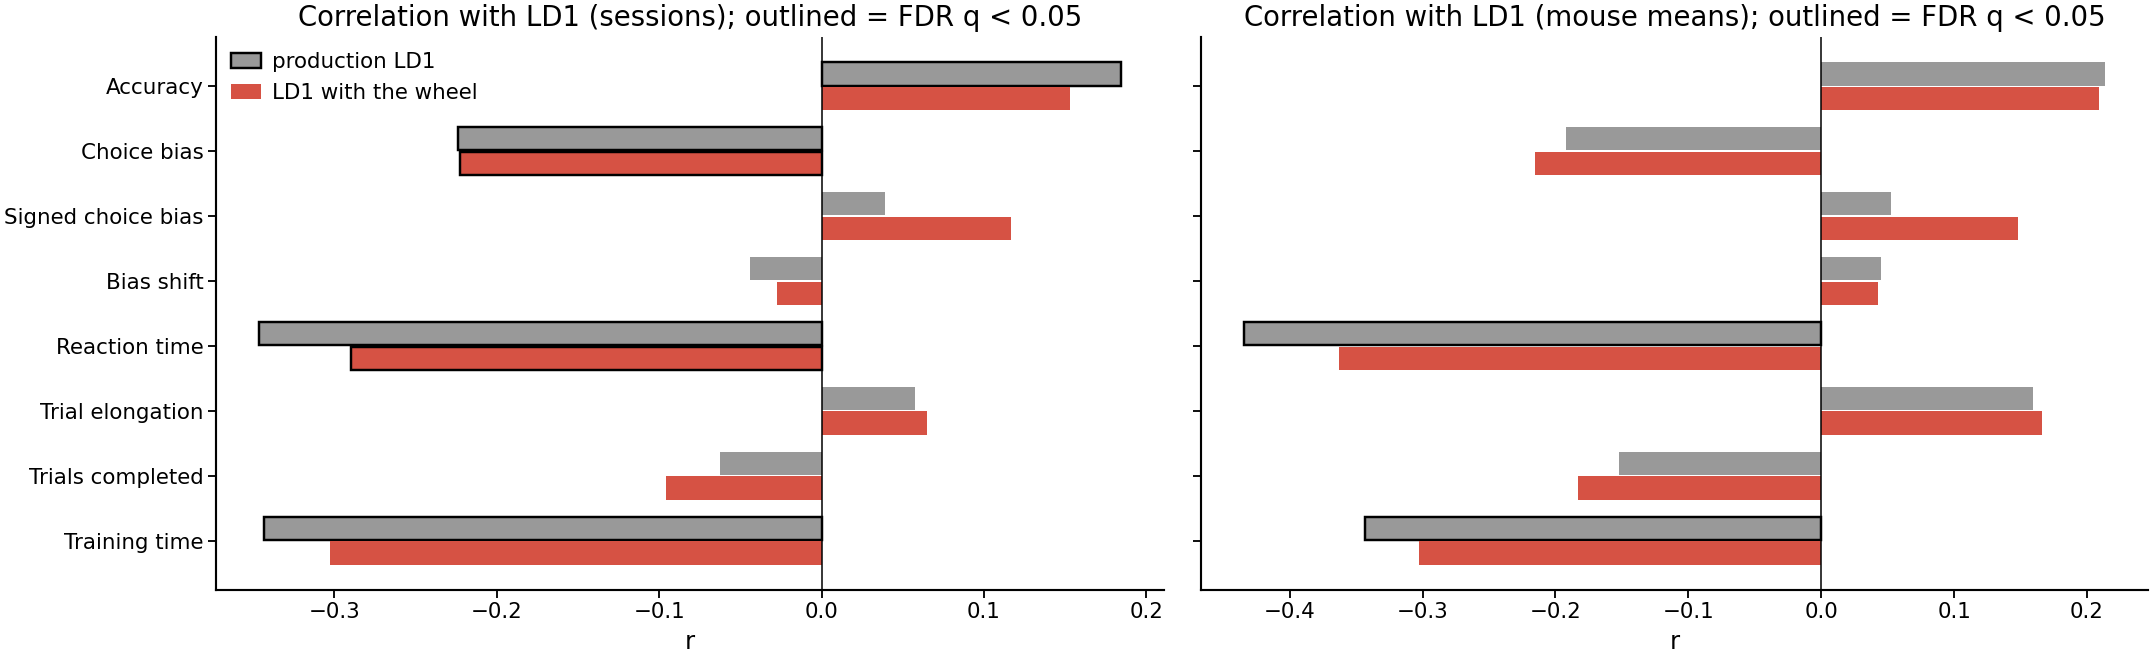

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
y = np.arange(len(C_VARS))
for ax, (rc, qc, title) in zip(axs, [('r', 'q', 'sessions'), ('r_mice', 'q_mice', 'mouse means')]):
    for j, (key, col, lab) in enumerate([('LD1_prod', '0.6', 'production LD1'), ('LD1_new', ps.LD1_CMAP(0.9), 'LD1 with the wheel')]):
        d = TS[TS.LD1 == key].set_index('measure').reindex([n for _, n in C_VARS])
        ax.barh(y + (j - 0.5) * 0.38, d[rc], height=0.36, color=col, label=lab,
                edgecolor=['k' if q < 0.05 else 'none' for q in d[qc]], lw=0.8)
    ax.axvline(0, color='k', lw=0.5); ax.set(title=f'Correlation with LD1 ({title}); outlined = FDR q < 0.05', xlabel='r')
axs[0].set_yticks(y, [n for _, n in C_VARS]); axs[0].invert_yaxis(); axs[0].legend(frameon=False, fontsize=7)
plt.tight_layout()